# 09 — Übersicht: Beste Hyperparameter aus 08 (alle Baskets/Kerzenlängen)

Liest **alle** gespeicherten Tuning-Läufe aus `08_tune_dynamic_vol.ipynb`
(`src.backtest.tuning.load_all_tuning_results`, egal ob automatische Alle-Baskets-Suche,
manuelles Widget-Panel, oder der Alle-Kerzenlängen-Auto-Modus) und baut daraus für jede
Basket×Kerzenlänge-Kombination einen **vollständigen, ausführlichen** Backtest mit
Kennzahlen, Trade-Analyse und mehreren Vergleichsgrafiken.

**Test vs. Validierung, ohne Data-Snooping:** Die Parameter in `08` wurden ausschliesslich
auf `CALIBRATION_RANGE` (älteste 80 % des verfügbaren Zeitraums) gesucht — `BACKTEST_RANGE`
(neueste 20 %) wurde dabei **nie** angefasst (`src.backtest.config.split_calibration_backtest`).
Dieses Notebook führt pro Kombination **einen** Backtest über den **gesamten** verfügbaren
Zeitraum aus und teilt danach Trades/Equity-Kurve in genau diese zwei Fenster:

- **Test** (`CALIBRATION_RANGE`) — in-sample bezüglich der Parameterwahl, zeigt wie gut die
  gefundenen Parameter zur Kalibrierungsperiode selbst passen.
- **Validierung** (`BACKTEST_RANGE`) — echtes Out-of-Sample, die Parameter haben diese Daten
  beim Tuning nie gesehen. Der Vergleich Test vs. Validierung ist der zentrale
  Overfitting-Check dieses Notebooks: bricht die Performance in der Validierung stark ein,
  sind die gefundenen Parameter vermutlich auf die Kalibrierungsperiode überangepasst.

Jede Kombination wird zusätzlich als eigenständiger Run über `src.backtest.runs.save_run`
gespeichert (Label-Suffix `-test`/`-validation`), damit sie auch in
`04_run_comparison.ipynb` auftaucht.

**Nicht direkt ausführen ohne mindestens einen gespeicherten Lauf aus `08`.** Ohne
gespeicherte Tuning-Ergebnisse unter `data/processed/tuning/` bricht Abschnitt 2 mit einer
klaren Fehlermeldung ab.

In [33]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))

import warnings
warnings.filterwarnings("ignore")

from dataclasses import replace as _dc_replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

from src.data import load_ohlcv_panel, load_symbol_map
from src.backtest.cliques import CliqueTimeline
from src.backtest.config import BacktestConfig, BasketParams, split_calibration_backtest, DateRange
from src.backtest.engine import BacktestEngine
from src.backtest import metrics as bt_metrics
from src.backtest import plots as bt_plots
from src.backtest import runs as bt_runs
from src.backtest import tuning as bt_tuning

print("Imports OK")

Imports OK


## 1. Run-Konfiguration

Muss zum Tuning-Lauf aus `08_tune_dynamic_vol.ipynb` passen, den dieses Notebook auswertet
(gleiches `DATA_START`/`DATA_END`/`BACKTEST_FRACTION`/`CLIQUE_VARIANT`/`STRATEGY_NAME`,
sonst ist `CALIBRATION_RANGE`/`BACKTEST_RANGE` nicht deckungsgleich mit dem, worauf die
gespeicherten `best_params` tatsächlich gesucht wurden).

In [34]:
RUN_LABEL_PREFIX = "tuning_overview"  # Praefix fuer die hier gespeicherten Runs

DATA_START = pd.Timestamp("2024-07-23", tz="UTC")   # muss zu 08_tune_dynamic_vol.ipynb passen
DATA_END = pd.Timestamp("2026-07-22", tz="UTC")
BACKTEST_FRACTION = 0.2  # identisch zu 08_tune_dynamic_vol.ipynb -- neueste 20% = Validierung

# NEU: fuer einen schnellen Funktionstest dieses Notebooks (nicht fuer echte Auswertung!)
# -- kuerzt Test- UND Validierungsfenster nach dem Split (Abschnitt 4) je auf 1/3 ihrer
# urspruenglichen Laenge, OHNE das 80/20-Verhaeltnis (BACKTEST_FRACTION) selbst zu aendern.
# Test wird dabei auf sein LETZTES Drittel gekuerzt, Validierung auf ihr ERSTES Drittel --
# beide bleiben direkt aneinander angrenzend, nur insgesamt weniger Bars zu simulieren
# (schnellere Panel-/Engine-Laufzeit). Fuer die Thesis QUICK_TEST=False lassen.
QUICK_TEST = True
QUICK_TEST_FRACTION = 1 / 3

# Basket 4 wie in 08_tune_dynamic_vol.ipynb ausgeschlossen (siehe dortige Begruendung:
# zu wenige Clique-Snapshots im gesamten Backtest-Zeitraum).
BASKETS = ("Basket 1", "Basket 2", "Basket 3")
CLIQUE_VARIANT = "raw_24h"
STRATEGY_NAME = "pairwise_zscore"
INITIAL_CAPITAL = 100_000.0

# BASE_PARAMS nur als Ausgangspunkt fuer Felder, die NICHT in den gespeicherten
# best_params stehen (z.B. wenn ein Tuning-Lauf nur einen Teil der Parameter gesucht hat) --
# symmetric_exit/dynamic_threshold_enabled/dynamic_sizing_enabled bleiben wie in 08 fest an.
BASE_PARAMS = BasketParams(
    entry_z=2.0, exit_z=0.5, stop_z=5.0,
    formation_window_candles=288 * 7,
    max_candidate_pairs=3, pair_prefilter_top_n=15,
    min_half_life_candles=6, max_half_life_candles=288 * 2,
    max_concurrent_positions=3,
    fee_bps=10.0, slippage_bps=2.0,
    symmetric_exit=True, dynamic_threshold_enabled=True, dynamic_sizing_enabled=True,
    vol_regime_lookback_candles=288, vol_regime_percentile_window_candles=60 * 288,
)

## 2. Tuning-Ergebnisse laden & beste Parameter je Basket/Kerzenlänge auswählen

In [35]:
all_tuning_df = bt_tuning.load_all_tuning_results()
if all_tuning_df.empty:
    raise SystemExit(
        "Keine gespeicherten Tuning-Laeufe unter data/processed/tuning/ gefunden -- "
        "zuerst 08_tune_dynamic_vol.ipynb (automatische Suche, Widget-Panel oder "
        "Alle-Kerzenlaengen-Auto-Modus) ausfuehren und mindestens einen Lauf speichern."
    )

print(f"{len(all_tuning_df)} gespeicherte Basket-Eintraege ueber {all_tuning_df['run_id'].nunique()} Laeufe gefunden.")
display(all_tuning_df.sort_values(["basket", "candle_minutes", "best_objective"], ascending=[True, True, False]))

# Pro (basket, candle_minutes) NUR den Eintrag mit dem hoechsten best_objective behalten --
# koennen mehrere sein, falls z.B. mehrfach mit derselben Kerzenlaenge getunt wurde.
BEST_PER_BASKET_CANDLE = (
    all_tuning_df.dropna(subset=["candle_minutes"])
    .sort_values("best_objective", ascending=False)
    .drop_duplicates(subset=["basket", "candle_minutes"])
    .sort_values(["basket", "candle_minutes"])
    .reset_index(drop=True)
)
print(f"\n{len(BEST_PER_BASKET_CANDLE)} eindeutige Basket x Kerzenlaenge-Kombinationen:")

# NEU: best_params (Dict pro Zeile) in eigene Spalten "entpacken", damit die
# tatsaechlich gewaehlten Hyperparameter direkt in der Uebersicht sichtbar sind,
# statt nur als undurchsichtiges Dict in einer Zelle. Interaktiv per Checkbox-
# Panel ein-/ausblendbar -- bei vielen Kombinationen sonst schnell unuebersichtlich.
_base_cols = ["run_id", "basket", "candle_minutes", "fee_preset", "best_objective", "n_trials", "n_folds"]
_param_cols = sorted({k for params in BEST_PER_BASKET_CANDLE["best_params"] for k in params})
BEST_PER_BASKET_CANDLE_EXPANDED = pd.concat(
    [BEST_PER_BASKET_CANDLE[_base_cols], pd.json_normalize(BEST_PER_BASKET_CANDLE["best_params"])[_param_cols]],
    axis=1,
)

w_overview_cols = widgets.SelectMultiple(
    options=_param_cols, value=tuple(_param_cols), description="Parameter:",
    layout=widgets.Layout(width="360px", height="140px"), style={"description_width": "80px"},
)
w_overview_output = widgets.Output()


def _update_overview_table(*_change):
    with w_overview_output:
        clear_output(wait=True)
        display(BEST_PER_BASKET_CANDLE_EXPANDED[_base_cols + list(w_overview_cols.value)])


w_overview_cols.observe(_update_overview_table, names="value")
display(widgets.VBox([
    widgets.HTML("<span style='font-size:0.85em; color:#888;'>Parameter-Spalten ein-/ausblenden (Mehrfachauswahl, Strg/Cmd-Klick):</span>"),
    w_overview_cols, w_overview_output,
]))
_update_overview_table()

8 gespeicherte Basket-Eintraege ueber 8 Laeufe gefunden.


,run_id,basket,candle_minutes,fee_preset,best_objective,n_trials,n_folds,best_params
0,20260817-192610_tune-pairwise-symmetric-dynami...,Basket 1,5,standard,-0.005778,20,8,"{'entry_z': 3.9525818748165986, 'entry_z_delta..."
1,20260817-201749_tune-pairwise-symmetric-dynami...,Basket 1,10,standard,-0.003664,20,8,"{'entry_z': 3.910552494721571, 'entry_z_delta'..."
2,20260817-205507_tune-pairwise-symmetric-dynami...,Basket 1,15,standard,-0.003029,20,8,"{'entry_z': 3.7890929570277194, 'entry_z_delta..."
3,20260817-210017_tune-pairwise-symmetric-dynami...,Basket 1,30,standard,-0.002489,20,8,"{'entry_z': 2.28949502915157, 'entry_z_delta':..."
4,20260818-022309_tune-pairwise-symmetric-dynami...,Basket 2,5,standard,-0.001235,20,8,"{'entry_z': 4.975414772459977, 'entry_z_delta'..."
5,20260818-043055_tune-pairwise-symmetric-dynami...,Basket 2,10,standard,-0.001381,20,8,"{'entry_z': 4.63570057373329, 'entry_z_delta':..."
6,20260818-054403_tune-pairwise-symmetric-dynami...,Basket 2,15,standard,-0.001801,20,8,"{'entry_z': 4.297279209156911, 'entry_z_delta'..."
7,20260818-093643_tune-pairwise-symmetric-dynami...,Basket 2,30,standard,-0.002127,20,8,"{'entry_z': 3.776637348463422, 'entry_z_delta'..."



8 eindeutige Basket x Kerzenlaenge-Kombinationen:


,run_id,basket,candle_minutes,fee_preset,best_objective,n_trials,n_folds
0,20260817-192610_tune-pairwise-symmetric-dynami...,Basket 1,5,standard,-0.005778,20,8
1,20260817-201749_tune-pairwise-symmetric-dynami...,Basket 1,10,standard,-0.003664,20,8
2,20260817-205507_tune-pairwise-symmetric-dynami...,Basket 1,15,standard,-0.003029,20,8
3,20260817-210017_tune-pairwise-symmetric-dynami...,Basket 1,30,standard,-0.002489,20,8
4,20260818-022309_tune-pairwise-symmetric-dynami...,Basket 2,5,standard,-0.001235,20,8
5,20260818-043055_tune-pairwise-symmetric-dynami...,Basket 2,10,standard,-0.001381,20,8
6,20260818-054403_tune-pairwise-symmetric-dynami...,Basket 2,15,standard,-0.001801,20,8
7,20260818-093643_tune-pairwise-symmetric-dynami...,Basket 2,30,standard,-0.002127,20,8


## 3. Daten laden

`PANEL_5M` einmal im 5-Min-Basisraster geladen, jede andere Kerzenlänge wird daraus per
`src.data.resample_ohlcv_panel` abgeleitet und gecacht -- analog zu `08_tune_dynamic_vol.ipynb`.

In [36]:
from src.data import resample_ohlcv_panel

id_to_symbol, symbol_to_id = load_symbol_map()

PANEL_5M = load_ohlcv_panel(start=DATA_START, end=DATA_END, fields=("open", "high", "low", "close"))
print(f"Panel (5min-Basis): {PANEL_5M['close'].shape[0]:,} Kerzen x {PANEL_5M['close'].shape[1]} Symbole")

timeline = CliqueTimeline.from_cache(
    variant=CLIQUE_VARIANT, id_to_symbol=id_to_symbol, baskets=list(BASKETS),
    start=DATA_START, end=DATA_END,
)
print(timeline.describe())

_panel_cache: dict[int, dict] = {5: PANEL_5M}


def get_panel_for_candle_minutes(candle_minutes: int) -> dict:
    if candle_minutes not in _panel_cache:
        _panel_cache[candle_minutes] = resample_ohlcv_panel(PANEL_5M, source_minutes=5, target_minutes=candle_minutes)
    return _panel_cache[candle_minutes]

Panel (5min-Basis): 209,953 Kerzen x 47 Symbole
Discovery-Intervall (Median über Baskets): 1 days 00:00:00
  Basket 1: 531 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 2: 605 Snapshots, 2024-07-29 00:00:00+00:00 → 2026-07-22 00:00:00+00:00, Intervall 1 days 00:00:00
  Basket 3: 459 Snapshots, 2024-08-05 00:00:00+00:00 → 2026-06-24 00:00:00+00:00, Intervall 1 days 00:00:00


## 4. Calibration/Backtest-Split (Test vs. Validierung)

Identisch zum Split, auf dem `08_tune_dynamic_vol.ipynb` die Parameter gesucht hat --
`CALIBRATION_RANGE` = Test-Fenster (in-sample bzgl. Parameterwahl), `BACKTEST_RANGE` =
Validierungs-Fenster (echtes Out-of-Sample, neueste 20 %).

In [37]:
CALIBRATION_RANGE, BACKTEST_RANGE = split_calibration_backtest(DATA_START, DATA_END, fraction=BACKTEST_FRACTION)
assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start

if QUICK_TEST:
    # Test (CALIBRATION_RANGE) auf ihr LETZTES Drittel kuerzen (naeher an BACKTEST_RANGE),
    # Validierung (BACKTEST_RANGE) auf ihr ERSTES Drittel kuerzen (naeher an CALIBRATION_RANGE)
    # -- beide bleiben direkt aneinander angrenzend, das 80/20-Gesamtverhaeltnis bleibt
    # unveraendert, nur die absolute Laenge (und damit die zu simulierenden Bars) sinkt.
    cal_days = (CALIBRATION_RANGE.end - CALIBRATION_RANGE.start).days + 1
    cal_third_days = max(1, round(cal_days * QUICK_TEST_FRACTION))
    CALIBRATION_RANGE = DateRange(CALIBRATION_RANGE.end - pd.Timedelta(days=cal_third_days - 1), CALIBRATION_RANGE.end)

    bt_days = (BACKTEST_RANGE.end - BACKTEST_RANGE.start).days + 1
    bt_third_days = max(1, round(bt_days * QUICK_TEST_FRACTION))
    BACKTEST_RANGE = DateRange(BACKTEST_RANGE.start, BACKTEST_RANGE.start + pd.Timedelta(days=bt_third_days - 1))

    print(f"QUICK_TEST aktiv -- Test/Validierung je auf {QUICK_TEST_FRACTION:.0%} ihrer urspruenglichen Laenge gekuerzt (nur fuer Funktionstest, nicht fuer die Thesis-Auswertung)." + chr(10))

assert CALIBRATION_RANGE.end < BACKTEST_RANGE.start
print(f"Test (= CALIBRATION_RANGE, in-sample):        {CALIBRATION_RANGE.start.date()} -> {CALIBRATION_RANGE.end.date()}")
print(f"Validierung (= BACKTEST_RANGE, out-of-sample): {BACKTEST_RANGE.start.date()} -> {BACKTEST_RANGE.end.date()}")

QUICK_TEST aktiv -- Test/Validierung je auf 33% ihrer urspruenglichen Laenge gekuerzt (nur fuer Funktionstest, nicht fuer die Thesis-Auswertung).

Test (= CALIBRATION_RANGE, in-sample):        2025-08-16 -> 2026-02-26
Validierung (= BACKTEST_RANGE, out-of-sample): 2026-02-27 -> 2026-04-16


## 5. Backtests ausführen (voller Zeitraum, danach in Test/Validierung geteilt)

Pro Zeile aus `BEST_PER_BASKET_CANDLE` (Basket × Kerzenlänge) **ein** Engine-Lauf über den
**gesamten** Zeitraum (`DATA_START`..`DATA_END`) mit den dort gespeicherten `best_params` --
danach werden Trades (`entry_timestamp`) und Equity-Kurve anhand von `CALIBRATION_RANGE`/
`BACKTEST_RANGE` in Test/Validierung aufgeteilt und **separat** ausgewertet
(`bt_metrics.compute_all_metrics`), ohne den Engine-Lauf selbst zu wiederholen -- ein
gemeinsamer Lauf über den vollen Zeitraum ist identisch zu zwei getrennten Läufen (keine
Re-Kalibrierung an der Nahtstelle, siehe G4 Look-Ahead-Guard), aber nur halb so teuer.

**Cache:** jedes `full_result` wird zusaetzlich unter `data/processed/tuning/_cache_09/`
als Pickle-Datei zwischengespeichert (Key = Hash aus `basket`/`candle_minutes`/`best_params`/
simuliertem Zeitraum). Bei einem erneuten Notebook-Lauf wird eine Kombination nur dann neu
gerechnet, wenn sich mindestens einer dieser Werte geaendert hat (z.B. weil
`08_tune_dynamic_vol.ipynb` fuer EINE Kerzenlaenge neu/besser getunt wurde) -- alle anderen,
unveraenderten Kombinationen kommen direkt aus dem Cache, ohne die Engine erneut laufen zu
lassen. `FORCE_RECOMPUTE = True` (Abschnitt 5-Code) erzwingt bei Bedarf einen kompletten
Neulauf, den Cache-Ordner selbst kann man jederzeit gefahrlos loeschen.

In [ ]:
def _slice_result(full_result, *, config, date_range: DateRange, benchmark_close):
    """Baut aus einem vollen BacktestResult ein Teil-Ergebnis fuer NUR date_range --
    Trades nach entry_timestamp gefiltert, Equity-Kurve auf den Zeitraum zugeschnitten
    (auf den Equity-Stand am Fensterbeginn normiert, damit total_return NICHT die
    Performance des jeweils anderen Fensters mitschleppt). config bekommt ein eigenes
    backtest_range=date_range, damit compute_all_metrics/metrics_by_basket exakt auf
    diesem Ausschnitt rechnen."""
    from src.backtest.types import BacktestResult

    window_kind = "test" if date_range == CALIBRATION_RANGE else "validation"
    sub_config = _dc_replace(
        config, backtest_range=date_range, calibration_range=None,
        label=f"{config.label}-{window_kind}",
    )

    trades = full_result.trades
    if not trades.empty:
        mask = (trades["entry_timestamp"] >= date_range.start) & (trades["entry_timestamp"] <= date_range.end)
        sub_trades = trades[mask].reset_index(drop=True)
    else:
        sub_trades = trades

    equity = full_result.equity_curve
    if not equity.empty:
        sub_equity = equity.loc[date_range.start:date_range.end].copy()
        if not sub_equity.empty and "equity" in sub_equity:
            sub_equity["equity"] = sub_equity["equity"] / sub_equity["equity"].iloc[0] * config.initial_capital
    else:
        sub_equity = equity

    sub_metrics = bt_metrics.compute_all_metrics(
        equity_curve=sub_equity, trades=sub_trades, benchmark_close=benchmark_close, config=sub_config,
    )
    sub_metrics_by_basket = bt_metrics.metrics_by_basket(sub_trades, sub_config)

    return BacktestResult(
        run_id=None, config=sub_config, equity_curve=sub_equity, trades=sub_trades,
        metrics=sub_metrics, metrics_by_basket=sub_metrics_by_basket,
        positions_curve=None, meta=dict(full_result.meta),
    )


# --- NEU: Backtest-Ergebnis-Cache (data/processed/tuning/_cache_09/) -----------
# Der Engine-Lauf (engine.run()) ist der mit Abstand teuerste Schritt dieser Zelle
# (mehrere Minuten pro Kombination bei 5min-Kerzen ueber den vollen Zeitraum). Ohne
# Cache muesste die GESAMTE Schleife neu laufen, sobald sich AUCH NUR EINE Kombination
# aendert (z.B. weil 08_tune_dynamic_vol.ipynb fuer eine einzelne Kerzenlaenge neu
# getunt wurde und bessere best_params liefert).
#
# Dateiname ist lesbar nach (basket, candle_minutes) benannt (z.B. "Basket-1_5min.pkl"),
# NICHT nach einem Hash -- macht den Cache-Ordner direkt inspizierbar/aufraeumbar. Die
# Zuordnung "passt dieser Cache-Eintrag noch zu den AKTUELL besten Parametern" passiert
# beim LADEN: gespeichert wird full_result GEMEINSAM mit den best_params, die zu seiner
# Berechnung gefuehrt haben (plus full_range, da sich der simulierte Zeitraum z.B. unter
# QUICK_TEST/Warm-up-Verschiebung aendern kann) -- weichen die im Cache hinterlegten
# best_params/full_range von den JETZT aus 08 geladenen besten Parametern ab (z.B. weil
# 08 zwischenzeitlich einen neuen, besseren Trial fuer genau dieses Basket+Kerzenlaenge
# gefunden hat), wird automatisch neu gerechnet statt den veralteten Cache zu verwenden.
import pickle

CACHE_DIR = bt_tuning.TUNING_DIR / "_cache_09"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FORCE_RECOMPUTE = False  # True = Cache ignorieren und ALLE Kombinationen neu rechnen


def _cache_path(basket: str, candle_minutes: int) -> Path:
    slug = basket.replace(" ", "-")
    return CACHE_DIR / f"{slug}_{candle_minutes}min.pkl"


def _load_cached_full_result(*, basket: str, candle_minutes: int, best_params: dict, full_range: DateRange):
    """Laedt den Cache-Eintrag fuer (basket, candle_minutes) NUR, wenn die darin
    hinterlegten best_params/full_range exakt zu den aktuell aus 08 geladenen besten
    Parametern passen -- best_params-Vergleich ueber sorted(items()), da dict-
    Reihenfolge zwischen JSON-Ladevorgaengen nicht garantiert identisch ist."""
    cache_path = _cache_path(basket, candle_minutes)
    if FORCE_RECOMPUTE or not cache_path.exists():
        return None
    try:
        with open(cache_path, "rb") as f:
            payload = pickle.load(f)
    except Exception as exc:  # noqa: BLE001 -- ein kaputter/inkompatibler Cache-Eintrag
        # (z.B. nach einer Aenderung an BacktestResult/BacktestConfig) darf den Lauf
        # nicht abbrechen, einfach neu rechnen statt zu crashen.
        print(f"  Cache-Eintrag {cache_path.name} konnte nicht geladen werden ({exc}) -- rechne neu.")
        return None

    cached_params_match = sorted(payload["best_params"].items()) == sorted(best_params.items())
    cached_range_match = (
        payload["full_range"].start == full_range.start and payload["full_range"].end == full_range.end
    )
    if not cached_params_match:
        print(f"  Cache {cache_path.name}: best_params haben sich geaendert (08 hat vermutlich neu/besser "
              f"getunt) -- verworfen, rechne neu.")
        return None
    if not cached_range_match:
        print(f"  Cache {cache_path.name}: simulierter Zeitraum hat sich geaendert (z.B. QUICK_TEST) -- "
              f"verworfen, rechne neu.")
        return None
    return payload["full_result"]


def _save_cached_full_result(*, basket: str, candle_minutes: int, best_params: dict, full_range: DateRange, full_result) -> None:
    payload = {"best_params": dict(best_params), "full_range": full_range, "full_result": full_result}
    with open(_cache_path(basket, candle_minutes), "wb") as f:
        pickle.dump(payload, f)
# --- Ende Cache-Helper -----------------------------------------------------------


FULL_RESULTS: dict[tuple[str, int], object] = {}   # (basket, candle_minutes) -> voller BacktestResult
TEST_RESULTS: dict[tuple[str, int], object] = {}
VALIDATION_RESULTS: dict[tuple[str, int], object] = {}
TEST_RUN_IDS: list[str] = []
VALIDATION_RUN_IDS: list[str] = []
SKIPPED_COMBINATIONS: list[dict] = []  # Kombinationen, die wegen zu grossem Warm-up uebersprungen wurden

for _, row in BEST_PER_BASKET_CANDLE.iterrows():
    basket, candle_minutes, best_params = row["basket"], int(row["candle_minutes"]), row["best_params"]
    print(f"\n{'=' * 70}\n{basket} @ {candle_minutes}min (run_id={row['run_id']})\n{'=' * 70}")

    panel = get_panel_for_candle_minutes(candle_minutes)
    params = _dc_replace(BASE_PARAMS, **best_params)

    # Warm-up-Puffer (G7): das Panel beginnt bei DATA_START (das frueheste ueberhaupt
    # verfuegbare Datum, siehe src.data.available_data_range -- davor existieren KEINE
    # Rohdaten), also kann full_range NICHT ebenfalls bei DATA_START beginnen, sonst
    # fehlt formation_window_candles/vol_regime_percentile_window_candles komplett die
    # Vorlauf-Historie. full_range.start wird deshalb um genau die fuer DIESE Parameter-
    # Kombination benoetigte Kerzenzahl (strategy.required_history_candles) nach hinten
    # verschoben -- pro Kombination unterschiedlich, weil best_params (v.a.
    # formation_window_candles/vol_regime_*) je nach Basket/Kerzenlaenge variieren, UND
    # weil dieselbe KerzenANZAHL bei laengeren Kerzen (z.B. 60min) viel mehr echte Zeit
    # bedeutet als bei 5min (ein Wert wie vol_regime_percentile_window_candles=25920 ist
    # bei 5min ~90 Tage, bei 60min aber ~1080 Tage).
    strategy = bt_tuning.build_strategy(STRATEGY_NAME)
    required_candles = strategy.required_history_candles(params)
    warmup_days = int(np.ceil(required_candles / bt_tuning.candles_per_day(candle_minutes)))
    range_start = max(DATA_START + pd.Timedelta(days=warmup_days), CALIBRATION_RANGE.start)

    # NEU: Guard -- falls der Warm-up-Bedarf so gross ist, dass fuer den eigentlichen
    # Backtest kein einziger Tag mehr uebrig bleibt (range_start >= DATA_END, siehe
    # required_candles-Kommentar oben), diese Kombination NUR protokollieren und
    # ueberspringen statt die gesamte Zelle mit einem ValueError aus dem Warm-up-Guard
    # (G7 in engine.py) abzubrechen -- schuetzt auch bei ECHTEN (nicht nur synthetischen)
    # Tuning-Ergebnissen, falls ein Optuna-Trial in 08 versehentlich unrealistisch grosse
    # Fensterparameter fuer eine bestimmte Kerzenlaenge gefunden hat.
    if range_start >= BACKTEST_RANGE.end:
        print(f"  UEBERSPRUNGEN: {warmup_days} Tage Warm-up noetig (aus {required_candles} Kerzen @ "
              f"{candle_minutes}min), aber nur {(BACKTEST_RANGE.end - DATA_START).days} Tage bis "
              f"BACKTEST_RANGE.end verfuegbar -- kein Backtest-Zeitraum uebrig.")
        SKIPPED_COMBINATIONS.append({
            "basket": basket, "candle_minutes": candle_minutes, "run_id": row["run_id"],
            "required_candles": required_candles, "warmup_days": warmup_days,
        })
        continue

    if range_start > CALIBRATION_RANGE.start:
        lost_days = (range_start - CALIBRATION_RANGE.start).days
        print(f"  Hinweis: {warmup_days} Tage Warm-up noetig (aus {required_candles} Kerzen) -- "
              f"Test-Fenster beginnt dadurch {lost_days} Tage nach CALIBRATION_RANGE.start.")
    # full_range.end = BACKTEST_RANGE.end (NICHT DATA_END) -- unter QUICK_TEST (Abschnitt 1/4)
    # ist BACKTEST_RANGE.end < DATA_END, die Engine soll dann auch nur bis dorthin simulieren,
    # sonst wuerde die Drittelung nur die AUSWERTUNG (_slice_result), nicht aber die
    # tatsaechliche Simulationsdauer verkuerzen. Ausserhalb von QUICK_TEST ist
    # BACKTEST_RANGE.end == DATA_END (siehe split_calibration_backtest), unveraendertes
    # Verhalten.
    full_range = DateRange(range_start, BACKTEST_RANGE.end)
    config = BacktestConfig(
        label=f"{RUN_LABEL_PREFIX}-{basket}-{candle_minutes}min",
        description=f"Voller Zeitraum, best_params aus Tuning-Lauf {row['run_id']} (objective={row['best_objective']:.4f}).",
        calibration_range=None, backtest_range=full_range,
        baskets=(basket,), clique_variant=CLIQUE_VARIANT, strategy_name=STRATEGY_NAME,
        default_params=params, initial_capital=INITIAL_CAPITAL, candle_minutes=candle_minutes,
    )
    benchmark_symbol = config.benchmark_symbol
    benchmark_close = panel["close"][benchmark_symbol] if benchmark_symbol in panel["close"].columns else None

    full_result = _load_cached_full_result(basket=basket, candle_minutes=candle_minutes, best_params=best_params, full_range=full_range)
    if full_result is not None:
        print(f"  Aus Cache geladen ({_cache_path(basket, candle_minutes).name}): {len(full_result.trades)} Trades -- kein Engine-Lauf noetig.")
    else:
        engine = BacktestEngine(config=config, panel=panel, timeline=timeline)
        # progress=True -- voller Zeitraum bei 5min-Kerzen sind ~210'000 Bars, ein Lauf kann
        # mehrere Minuten dauern; ohne Fortschrittsbalken (tqdm) sieht das wie ein Haenger aus.
        full_result = engine.run(progress=True)
        full_result.metrics = bt_metrics.compute_all_metrics(
            equity_curve=full_result.equity_curve, trades=full_result.trades,
            benchmark_close=benchmark_close, config=config,
        )
        full_result.metrics_by_basket = bt_metrics.metrics_by_basket(full_result.trades, config)
        _save_cached_full_result(basket=basket, candle_minutes=candle_minutes, best_params=best_params, full_range=full_range, full_result=full_result)
        print(f"Voller Zeitraum: {len(full_result.trades)} Trades (neu berechnet, in Cache gespeichert: {_cache_path(basket, candle_minutes).name})")

    key = (basket, candle_minutes)
    FULL_RESULTS[key] = full_result

    test_result = _slice_result(full_result, config=config, date_range=CALIBRATION_RANGE, benchmark_close=benchmark_close)
    validation_result = _slice_result(full_result, config=config, date_range=BACKTEST_RANGE, benchmark_close=benchmark_close)
    TEST_RESULTS[key] = test_result
    VALIDATION_RESULTS[key] = validation_result
    print(f"  Test (in-sample):        {len(test_result.trades)} Trades | sharpe_daily={test_result.metrics.get('sharpe_daily', float('nan')):.3f}")
    print(f"  Validierung (out-of-sample): {len(validation_result.trades)} Trades | sharpe_daily={validation_result.metrics.get('sharpe_daily', float('nan')):.3f}")

    test_result.meta["source_tuning_run_id"] = row["run_id"]
    validation_result.meta["source_tuning_run_id"] = row["run_id"]
    test_dir = bt_runs.save_run(test_result)
    validation_dir = bt_runs.save_run(validation_result)
    TEST_RUN_IDS.append(test_result.run_id)
    VALIDATION_RUN_IDS.append(validation_result.run_id)

print(f"\n\nFertig: {len(FULL_RESULTS)} Kombinationen, je 2 Runs gespeichert (Test + Validierung).")
if SKIPPED_COMBINATIONS:
    print(f"{len(SKIPPED_COMBINATIONS)} Kombination(en) uebersprungen (Warm-up-Bedarf > verfuegbarer Zeitraum):")
    for skip in SKIPPED_COMBINATIONS:
        print(f"  - {skip['basket']} @ {skip['candle_minutes']}min (run_id={skip['run_id']}): "
              f"{skip['warmup_days']} Tage Warm-up noetig")


Basket 1 @ 5min (run_id=20260817-192610_tune-pairwise-symmetric-dynamic-vol-full-stopz5-widget-basket-1-5min-standard)


100%|██████████| 69985/69985 [02:34<00:00, 454.05it/s] 


Voller Zeitraum: 46 Trades
  Test (in-sample):        35 Trades | sharpe_daily=-2.533
  Validierung (out-of-sample): 11 Trades | sharpe_daily=0.761

Basket 1 @ 10min (run_id=20260817-201749_tune-pairwise-symmetric-dynamic-vol-full-stopz5-widget-basket-1-10min-standard)


100%|██████████| 34993/34993 [01:00<00:00, 574.88it/s] 


Voller Zeitraum: 30 Trades
  Test (in-sample):        24 Trades | sharpe_daily=1.663
  Validierung (out-of-sample): 6 Trades | sharpe_daily=-2.726

Basket 1 @ 15min (run_id=20260817-205507_tune-pairwise-symmetric-dynamic-vol-full-stopz5-widget-basket-1-15min-standard)


100%|██████████| 23329/23329 [01:02<00:00, 374.73it/s]


Voller Zeitraum: 34 Trades
  Test (in-sample):        27 Trades | sharpe_daily=2.637
  Validierung (out-of-sample): 7 Trades | sharpe_daily=-4.635

Basket 1 @ 30min (run_id=20260817-210017_tune-pairwise-symmetric-dynamic-vol-full-stopz5-widget-basket-1-30min-standard)
  Hinweis: 474 Tage Warm-up noetig (aus 22732 Kerzen) -- Test-Fenster beginnt dadurch 85 Tage nach CALIBRATION_RANGE.start.


 55%|█████▌    | 4176/7585 [00:27<00:15, 214.41it/s]

## 6. Kennzahlen-Vergleich

Alle Test-Runs (in-sample) und Validierungs-Runs (out-of-sample) nebeneinander --
`src.backtest.runs.compare_runs` hebt pro Zeile den besten Wert farblich hervor.

In [ ]:
print("### Validierung (out-of-sample, neueste 20% -- die eigentlich massgebliche Zahl)")
display(bt_runs.compare_runs(VALIDATION_RUN_IDS))

print("\n### Test (in-sample, aelteste 80% -- zum Vergleich mit der Validierung)")
display(bt_runs.compare_runs(TEST_RUN_IDS))

### Validierung (out-of-sample, neueste 20% -- die eigentlich massgebliche Zahl)


,20260817-221230_tuning-overview-basket-1-5min-validation_4ea0b89b,20260817-221335_tuning-overview-basket-1-10min-validation_24b46d40,20260817-221435_tuning-overview-basket-1-15min-validation_c3f5eba1,20260817-221526_tuning-overview-basket-1-30min-validation_69b9d670
cagr_daily,0.005042,-0.034183,-0.048142,-0.049164
ann_volatility_daily,0.006634,0.012728,0.010631,0.022758
sharpe_daily,0.761441,-2.726285,-4.635468,-2.203895
sortino_daily,1.220349,-3.163174,-4.959418,-3.193872
calmar_daily,2.740695,-4.624858,-6.694499,-3.485340
max_drawdown_pct,-0.002949,-0.008821,-0.008636,-0.014750
max_drawdown_dollar,-295.260699,-884.432698,-865.456914,-1486.384874
beta_vs_benchmark,0.001817,-0.007298,-0.004909,0.000818
alpha_annualized_vs_benchmark,0.003452,-0.027954,-0.043951,-0.049612
n_trades,11.000000,6.000000,7.000000,29.000000



### Test (in-sample, aelteste 80% -- zum Vergleich mit der Validierung)


,20260817-221230_tuning-overview-basket-1-5min-test_76018cc9,20260817-221335_tuning-overview-basket-1-10min-test_3db931e6,20260817-221435_tuning-overview-basket-1-15min-test_e1d0ace3,20260817-221525_tuning-overview-basket-1-30min-test_4a0c7550
cagr_daily,-0.025402,0.017793,0.029552,-0.038471
ann_volatility_daily,0.010136,0.010638,0.011066,0.025694
sharpe_daily,-2.533439,1.663138,2.637368,-1.514012
sortino_daily,-2.894966,2.841067,4.511601,-1.983951
calmar_daily,-1.868480,3.700705,4.731656,-2.937417
max_drawdown_pct,-0.014137,-0.006084,-0.007654,-0.013956
max_drawdown_dollar,-1414.253230,-610.727751,-782.859352,-1398.913985
beta_vs_benchmark,0.000732,0.001515,0.001454,-0.011731
alpha_annualized_vs_benchmark,-0.024696,0.019248,0.030953,-0.051316
n_trades,35.000000,24.000000,27.000000,69.000000


## 7. Test vs. Validierung -- Overfitting-Check

Zeigt pro Basket/Kerzenlänge, wie stark die Performance zwischen Test (in-sample) und Validierung (out-of-sample) auseinanderläuft. Ein grosser negativer `validation_minus_test`-Wert deutet auf Überanpassung an die Kalibrierungsperiode hin.

,basket,candle_minutes,sharpe_test,sharpe_validation,cagr_test,cagr_validation,max_dd_test,max_dd_validation,n_trades_test,n_trades_validation,sharpe_validation_minus_test
0,Basket 1,5,-2.533439,0.761441,-0.025402,0.005042,-0.014137,-0.002949,35,11,3.294880
1,Basket 1,10,1.663138,-2.726285,0.017793,-0.034183,-0.006084,-0.008821,24,6,-4.389423
2,Basket 1,15,2.637368,-4.635468,0.029552,-0.048142,-0.007654,-0.008636,27,7,-7.272835
3,Basket 1,30,-1.514012,-2.203895,-0.038471,-0.049164,-0.013956,-0.014750,69,29,-0.689883


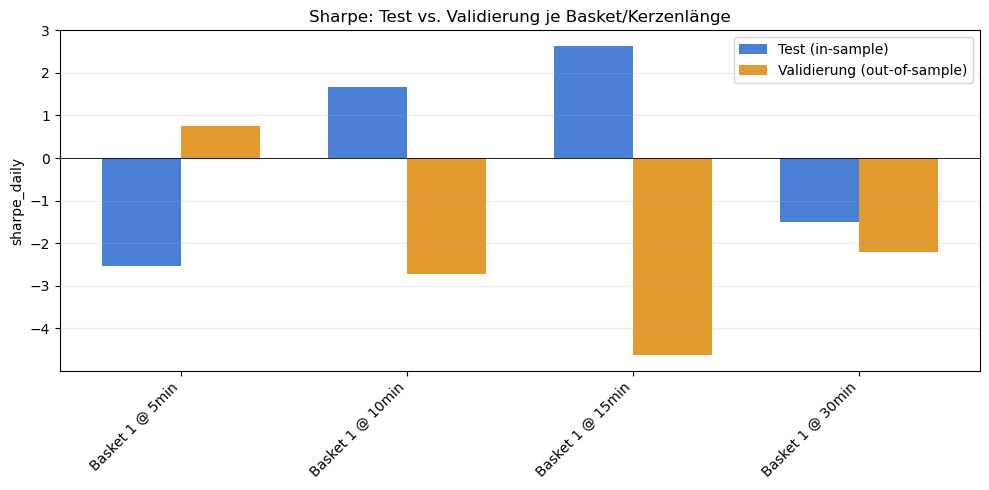

In [ ]:
rows = []
for (basket, candle_minutes), test_result in TEST_RESULTS.items():
    validation_result = VALIDATION_RESULTS[(basket, candle_minutes)]
    rows.append({
        "basket": basket, "candle_minutes": candle_minutes,
        "sharpe_test": test_result.metrics.get("sharpe_daily", np.nan),
        "sharpe_validation": validation_result.metrics.get("sharpe_daily", np.nan),
        "cagr_test": test_result.metrics.get("cagr_daily", np.nan),
        "cagr_validation": validation_result.metrics.get("cagr_daily", np.nan),
        "max_dd_test": test_result.metrics.get("max_drawdown_pct", np.nan),
        "max_dd_validation": validation_result.metrics.get("max_drawdown_pct", np.nan),
        "n_trades_test": test_result.metrics.get("n_trades", 0),
        "n_trades_validation": validation_result.metrics.get("n_trades", 0),
    })
overfit_df = pd.DataFrame(rows)
overfit_df["sharpe_validation_minus_test"] = overfit_df["sharpe_validation"] - overfit_df["sharpe_test"]
overfit_df = overfit_df.sort_values(["basket", "candle_minutes"]).reset_index(drop=True)
display(overfit_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(overfit_df))
width = 0.35
labels = overfit_df["basket"].astype(str) + " @ " + overfit_df["candle_minutes"].astype(str) + "min"
ax.bar(x - width/2, overfit_df["sharpe_test"], width, label="Test (in-sample)", color="#4a7fd6")
ax.bar(x + width/2, overfit_df["sharpe_validation"], width, label="Validierung (out-of-sample)", color="#e39a2e")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_ylabel("sharpe_daily")
ax.set_title("Sharpe: Test vs. Validierung je Basket/Kerzenlänge")
ax.legend()
ax.grid(True, alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

## 8. Equity-Kurven (normiert) -- alle Kombinationen, Validierungsfenster

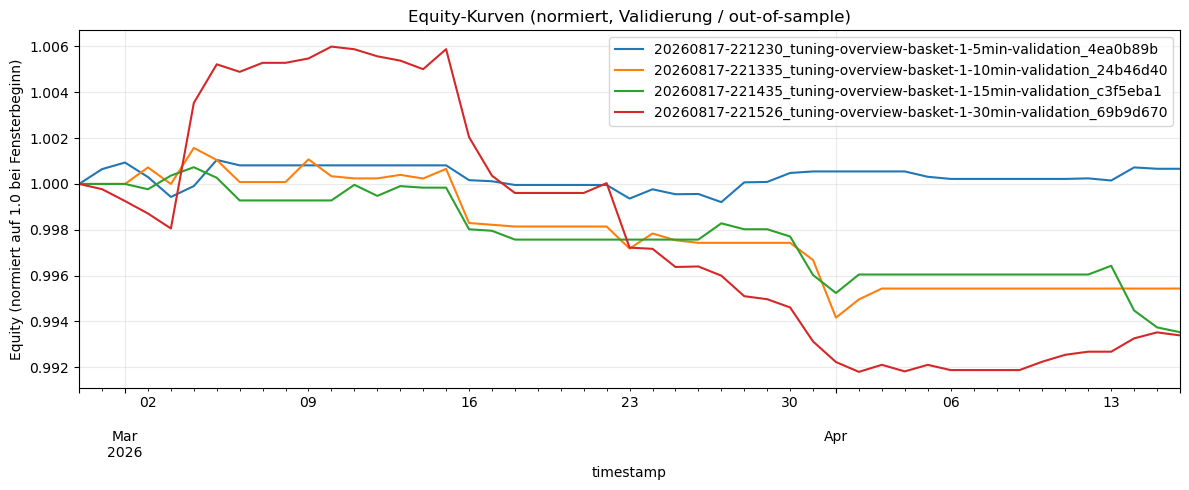

In [ ]:
curves = bt_runs.compare_equity_curves(VALIDATION_RUN_IDS)
if not curves.empty:
    ax = curves.plot(figsize=(12, 5), title="Equity-Kurven (normiert, Validierung / out-of-sample)")
    ax.set_ylabel("Equity (normiert auf 1.0 bei Fensterbeginn)")
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("Keine Equity-Kurven zum Plotten (leere Trades in allen Validierungs-Runs?).")

## 9. Equity & Drawdown je Kombination (Validierung)


### Basket 1 @ 5min (Validierung)


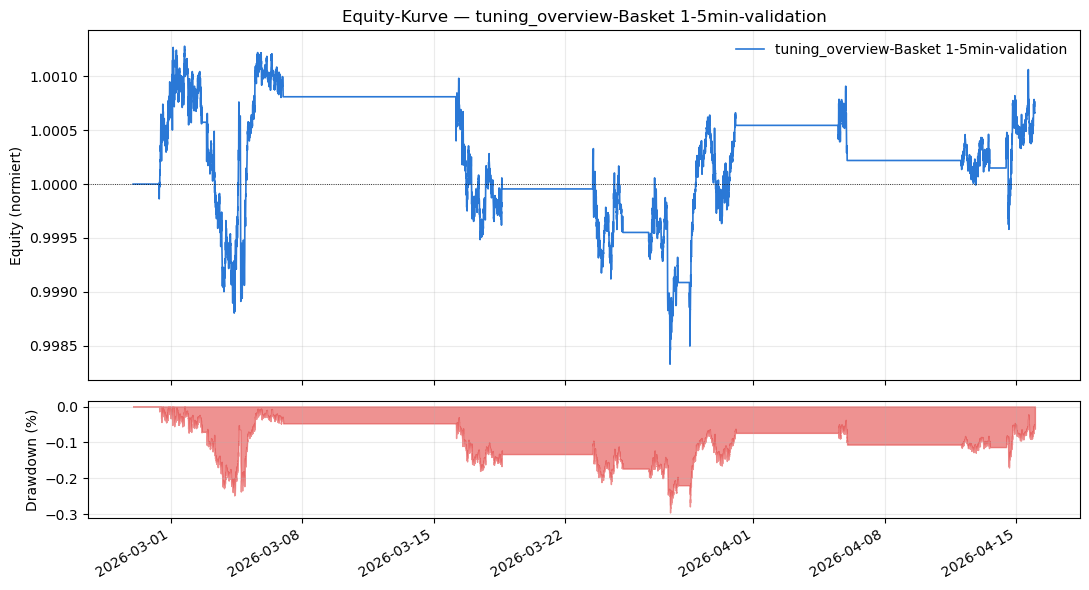


### Basket 1 @ 10min (Validierung)


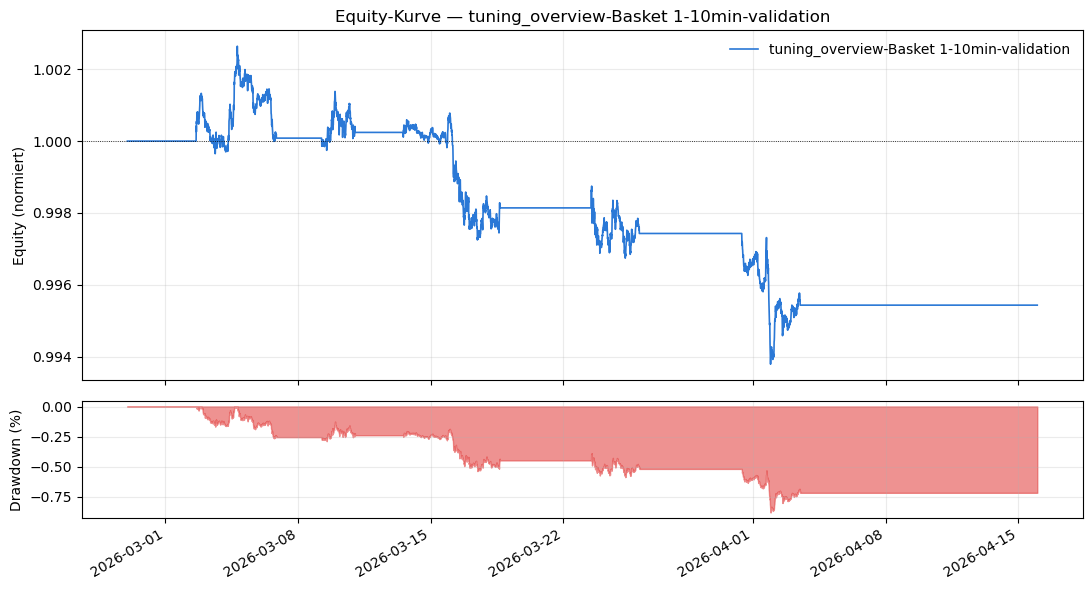


### Basket 1 @ 15min (Validierung)


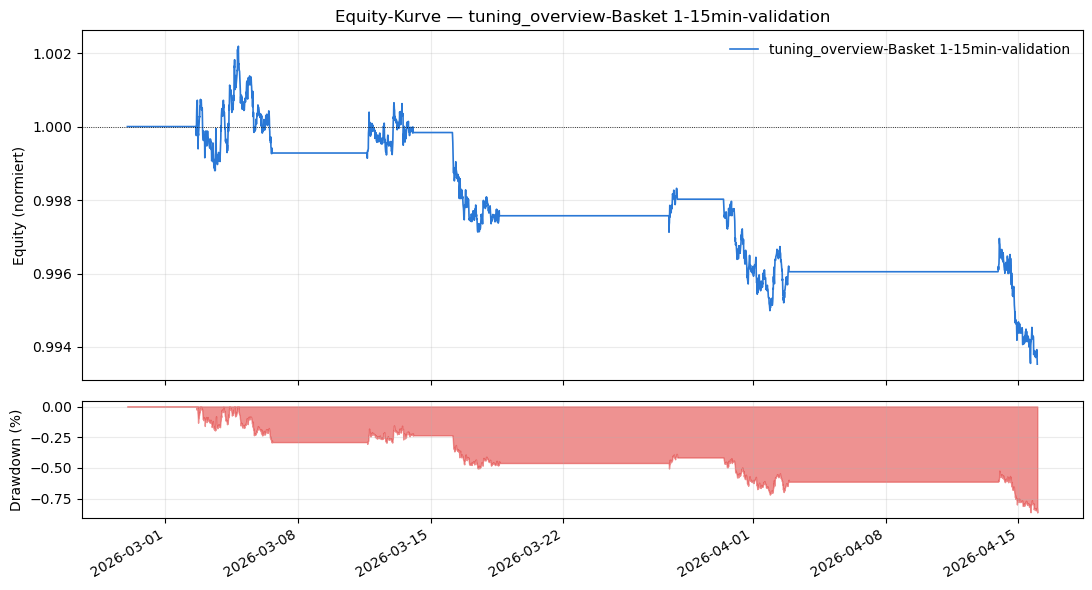


### Basket 1 @ 30min (Validierung)


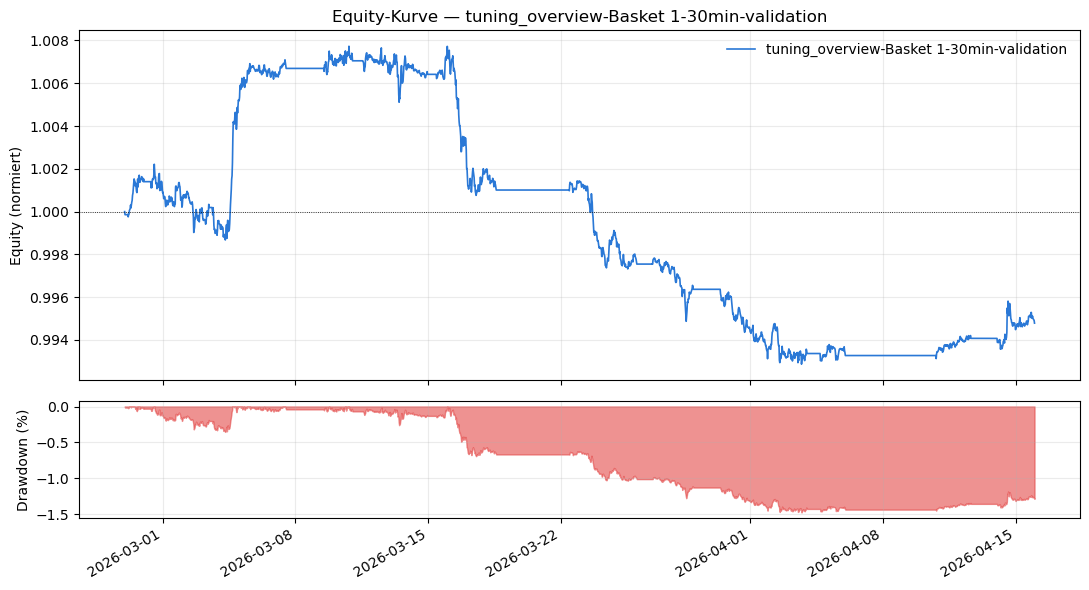

In [ ]:
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if result.equity_curve.empty:
        print(f"{basket} @ {candle_minutes}min: keine Trades in der Validierung, kein Plot.")
        continue
    print(f"\n### {basket} @ {candle_minutes}min (Validierung)")
    bt_plots.plot_equity_and_drawdown(result, benchmark_close=None)

## 10. Trade-Verteilung nach Exit-Grund

In [ ]:
print("### Validierung (out-of-sample)")
display(bt_runs.compare_trade_distributions(VALIDATION_RUN_IDS))

print("\n### Test (in-sample)")
display(bt_runs.compare_trade_distributions(TEST_RUN_IDS))

### Validierung (out-of-sample)


,exit_reason,count,mean,sum,run_id
0,clique_break,2,-39.016273,-78.032546,20260817-221230_tuning-overview-basket-1-5min-...
1,stop,1,-99.917781,-99.917781,20260817-221230_tuning-overview-basket-1-5min-...
2,target,2,74.850984,149.701967,20260817-221230_tuning-overview-basket-1-5min-...
3,timeout,6,15.585537,93.513220,20260817-221230_tuning-overview-basket-1-5min-...
4,clique_break,2,-27.878384,-55.756769,20260817-221335_tuning-overview-basket-1-10min...
5,stop,1,-115.805979,-115.805979,20260817-221335_tuning-overview-basket-1-10min...
6,target,1,-96.177505,-96.177505,20260817-221335_tuning-overview-basket-1-10min...
7,timeout,2,-96.455709,-192.911418,20260817-221335_tuning-overview-basket-1-10min...
8,clique_break,1,45.781927,45.781927,20260817-221435_tuning-overview-basket-1-15min...
9,end_of_backtest,1,-255.569849,-255.569849,20260817-221435_tuning-overview-basket-1-15min...



### Test (in-sample)


,exit_reason,count,mean,sum,run_id
0,clique_break,10,-40.068571,-400.685712,20260817-221230_tuning-overview-basket-1-5min-...
1,stop,5,-31.376454,-156.882268,20260817-221230_tuning-overview-basket-1-5min-...
2,target,5,44.508869,222.544343,20260817-221230_tuning-overview-basket-1-5min-...
3,timeout,15,-68.216047,-1023.240704,20260817-221230_tuning-overview-basket-1-5min-...
4,clique_break,5,19.593445,97.967224,20260817-221335_tuning-overview-basket-1-10min...
5,stop,6,-80.042924,-480.257545,20260817-221335_tuning-overview-basket-1-10min...
6,target,7,120.661188,844.628314,20260817-221335_tuning-overview-basket-1-10min...
7,timeout,6,79.907075,479.442448,20260817-221335_tuning-overview-basket-1-10min...
8,clique_break,14,15.233987,213.275819,20260817-221435_tuning-overview-basket-1-15min...
9,target,5,270.315111,1351.575554,20260817-221435_tuning-overview-basket-1-15min...


## 11. Exit-Gründe & PnL-Verteilung je Kombination (Validierung)


### Basket 1 @ 5min (Validierung)


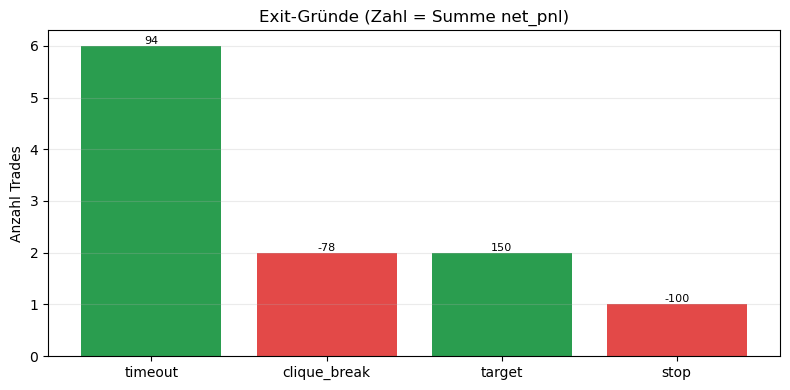

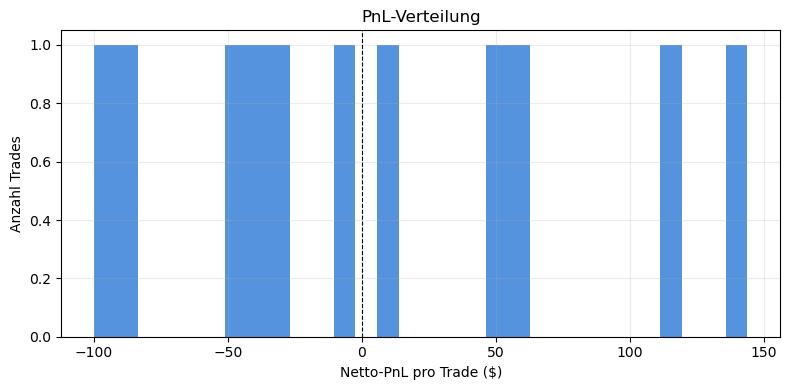


### Basket 1 @ 10min (Validierung)


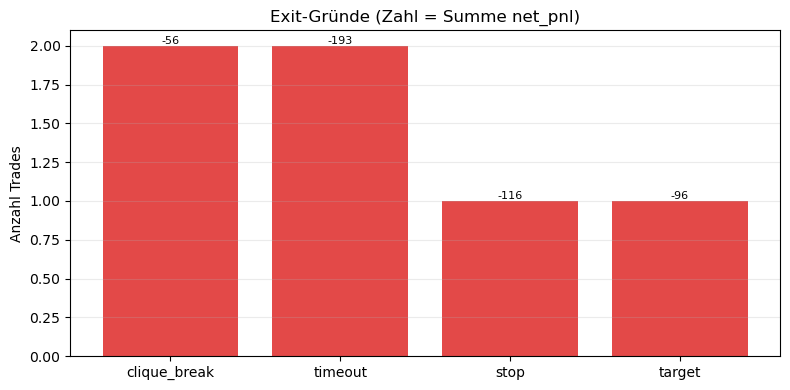

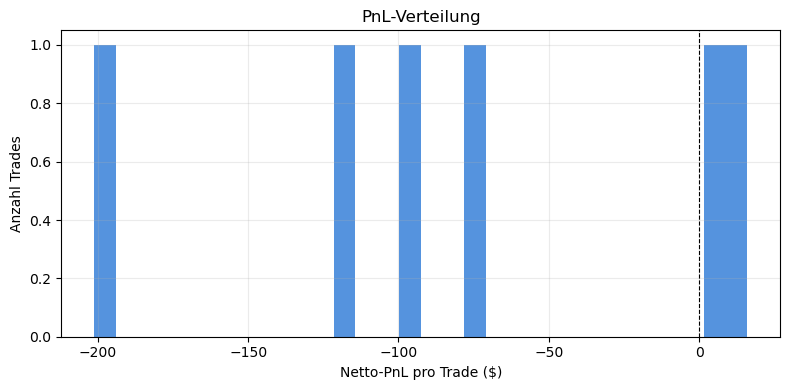


### Basket 1 @ 15min (Validierung)


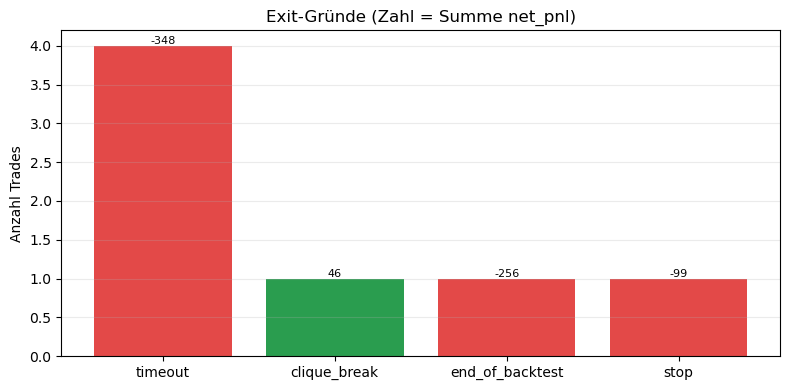

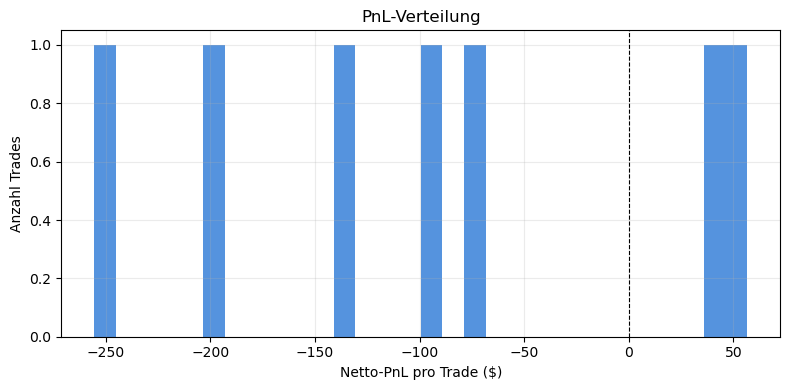


### Basket 1 @ 30min (Validierung)


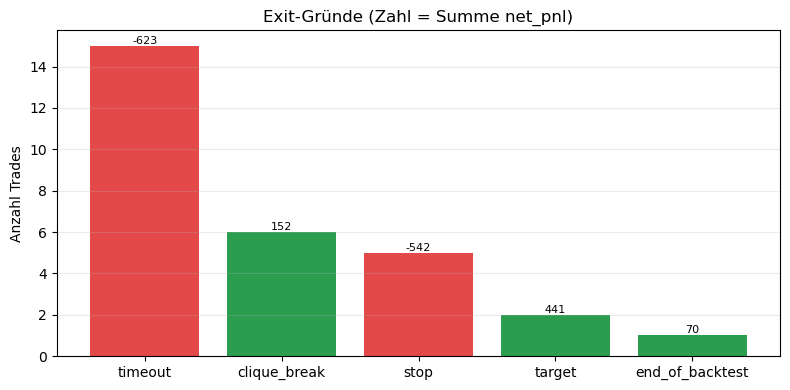

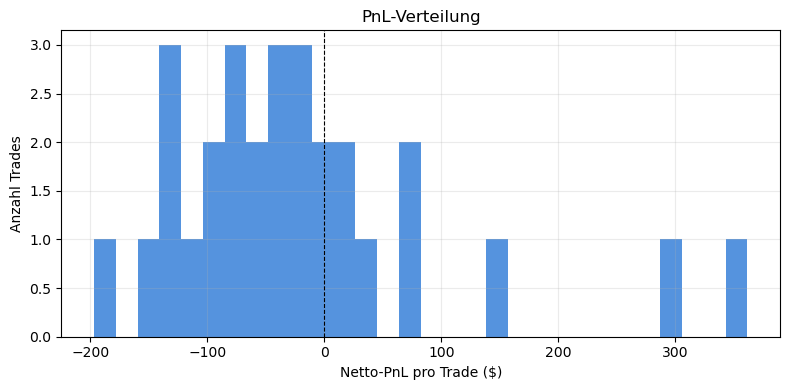

In [ ]:
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if result.trades.empty:
        continue
    print(f"\n### {basket} @ {candle_minutes}min (Validierung)")
    bt_plots.plot_exit_reason_breakdown(result.trades)
    bt_plots.plot_pnl_distribution(result.trades)

## 11b. Vola-Regime-Verteilung der Trades

Wie viele Trades wurden in welchem Vola-Regime eröffnet (Low/Normal/High, siehe PDF A.2 --
`src.backtest.strategy._resolve_entry_threshold_and_sizing`)? Regime wird pro Trade aus
`entry_threshold_z` (dem bei Entry tatsächlich gültigen, ggf. regimeabhängig verschobenen
Schwellenwert, siehe `src/backtest/portfolio.py`) im Vergleich zum Basis-`entry_z` des
jeweiligen Baskets abgeleitet: `entry_threshold_z < entry_z` → Low-Vol (engere Schwelle),
`entry_threshold_z > entry_z` → High-Vol (weitere Schwelle), sonst Normal (oder
`dynamic_threshold_enabled=False`). Zeigt u.a., ob der Regime-Mechanismus überhaupt
nennenswert oft greift, oder ob der Markt im Backtest-Zeitraum meist "Normal" war.

In [ ]:
def _classify_trade_regime(trades: pd.DataFrame, config: BacktestConfig) -> pd.Series:
    """entry_threshold_z vs. params_for(basket).entry_z -> "low"/"normal"/"high" pro Trade.
    Toleranz 1e-9 gegen Float-Rundung (z.B. entry_threshold_z == entry_z nach einem
    max(..., 0.1)-Clamp in _resolve_entry_threshold_and_sizing)."""
    if trades.empty:
        return pd.Series(dtype=str)

    def _regime_for_row(row):
        base_entry_z = config.params_for(row["basket"]).entry_z
        delta = row["entry_threshold_z"] - base_entry_z
        if delta < -1e-9:
            return "low"
        if delta > 1e-9:
            return "high"
        return "normal"

    return trades.apply(_regime_for_row, axis=1)


w_regime_basket = widgets.Dropdown(
    options=["(alle)"] + sorted({b for b, _ in VALIDATION_RESULTS}), value="(alle)",
    description="Basket:", style={"description_width": "140px"},
)
w_regime_candle = widgets.Dropdown(
    options=["(alle)"] + sorted({cm for _, cm in VALIDATION_RESULTS}), value="(alle)",
    description="Kerzenlänge (min):", style={"description_width": "140px"},
)
w_regime_output = widgets.Output()


def _update_regime_overview(*_change):
    with w_regime_output:
        clear_output(wait=True)
        rows = []
        for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
            if w_regime_basket.value != "(alle)" and basket != w_regime_basket.value:
                continue
            if w_regime_candle.value != "(alle)" and candle_minutes != w_regime_candle.value:
                continue
            if result.trades.empty:
                continue
            regimes = _classify_trade_regime(result.trades, result.config)
            counts = regimes.value_counts().reindex(["low", "normal", "high"], fill_value=0)
            pnl_by_regime = result.trades.assign(regime=regimes).groupby("regime")["net_pnl"].sum().reindex(["low", "normal", "high"], fill_value=0.0)
            for regime in ("low", "normal", "high"):
                rows.append({
                    "basket": basket, "candle_minutes": candle_minutes, "regime": regime,
                    "n_trades": int(counts[regime]), "net_pnl": float(pnl_by_regime[regime]),
                })
        regime_df = pd.DataFrame(rows)
        if regime_df.empty:
            print("Keine Trades für diese Auswahl.")
            return

        pivot_counts = regime_df.pivot_table(index=["basket", "candle_minutes"], columns="regime", values="n_trades", fill_value=0)
        pivot_counts = pivot_counts.reindex(columns=["low", "normal", "high"], fill_value=0)
        display(pivot_counts)

        totals = regime_df.groupby("regime")["n_trades"].sum().reindex(["low", "normal", "high"], fill_value=0)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        colors = {"low": "#4a9fd6", "normal": "#999999", "high": "#e39a2e"}
        ax1.bar(totals.index, totals.values, color=[colors[r] for r in totals.index])
        ax1.set_ylabel("Anzahl Trades")
        ax1.set_title("Trades je Regime (Summe über Auswahl)")
        ax1.grid(True, alpha=0.25, axis="y")

        pnl_totals = regime_df.groupby("regime")["net_pnl"].sum().reindex(["low", "normal", "high"], fill_value=0.0)
        bar_colors = ["#2a9d4f" if v >= 0 else "#e34948" for v in pnl_totals.values]
        ax2.bar(pnl_totals.index, pnl_totals.values, color=bar_colors)
        ax2.axhline(0, color="black", linewidth=0.6)
        ax2.set_ylabel("net_pnl ($)")
        ax2.set_title("PnL je Regime (Summe über Auswahl)")
        ax2.grid(True, alpha=0.25, axis="y")
        plt.tight_layout()
        plt.show()


w_regime_basket.observe(_update_regime_overview, names="value")
w_regime_candle.observe(_update_regime_overview, names="value")
display(widgets.VBox([widgets.HBox([w_regime_basket, w_regime_candle]), w_regime_output]))
_update_regime_overview()

## 11c. Trade-Explorer: Spread, Bollinger-Bänder, Ein-/Ausstieg & Z-Score

Interaktives Panel -- Basket/Kerzenlänge/Trade auswählen, zeigt zwei übereinander liegende
Plots für den gewählten Trade:

- **Oben:** rekonstruierter Spread mit rollierenden Bollinger-Bändern (Mittelwert ±
  `entry_z`/`exit_z`/`stop_z` · Std, siehe `src.backtest.plots.plot_trade_bollinger`) sowie
  Entry-/Exit-Markern und farblich markierter Haltedauer.
- **Unten:** derselbe Zeitraum als Z-Score-Verlauf ((Spread − Mittelwert) / Std) mit den
  relevanten Schwellenlinien (`entry_threshold_z` -- der bei DIESEM Trade tatsächlich
  gültige, ggf. regimeabhängig verschobene Wert -- sowie `exit_z`/`stop_z`), damit direkt
  sichtbar ist, bei welchem Z-Wert Entry/Exit stattfanden und wie nah am Stop die Position
  zwischenzeitlich war.

In [ ]:
from src.backtest.plots import _reconstruct_spread_band

_explorer_baskets = sorted({b for b, _ in VALIDATION_RESULTS})
w_te_basket = widgets.Dropdown(options=_explorer_baskets, value=_explorer_baskets[0] if _explorer_baskets else None, description="Basket:", style={"description_width": "140px"})
w_te_candle = widgets.Dropdown(options=sorted({cm for _, cm in VALIDATION_RESULTS}), description="Kerzenlänge (min):", style={"description_width": "140px"})
w_te_trade = widgets.Dropdown(description="Trade:", style={"description_width": "140px"}, layout=widgets.Layout(width="600px"))
w_te_buffer = widgets.IntSlider(value=144, min=24, max=576, step=24, description="Puffer (Kerzen):", style={"description_width": "140px"}, layout=widgets.Layout(width="420px"))
w_te_output = widgets.Output()


def _te_trade_label(row) -> str:
    symbols = "/".join(row["symbols"])
    return (f"{row['entry_timestamp']:%Y-%m-%d %H:%M} | {symbols} | {row['exit_reason']} | "
            f"net_pnl={row['net_pnl']:.1f}$")


def _te_update_trade_options(*_change):
    key = (w_te_basket.value, w_te_candle.value)
    result = VALIDATION_RESULTS.get(key)
    if result is None or result.trades.empty:
        w_te_trade.options = []
        return
    trades = result.trades.sort_values("entry_timestamp")
    w_te_trade.options = [(_te_trade_label(row), i) for i, row in trades.iterrows()]


def _te_plot_selected_trade(*_change):
    with w_te_output:
        clear_output(wait=True)
        key = (w_te_basket.value, w_te_candle.value)
        result = VALIDATION_RESULTS.get(key)
        if result is None or w_te_trade.value is None or result.trades.empty:
            print("Kein Trade für diese Auswahl.")
            return
        trade = result.trades.loc[w_te_trade.value]
        params = result.config.params_for(trade["basket"])
        widget_panel_te = get_panel_for_candle_minutes(w_te_candle.value)

        fig, (ax_spread, ax_z) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

        bt_plots.plot_trade_bollinger(trade, widget_panel_te, params, buffer_candles=w_te_buffer.value, ax=ax_spread, show=False)

        band = _reconstruct_spread_band(
            trade, widget_panel_te, bollinger_window_candles=params.bollinger_window_candles,
            buffer_candles=w_te_buffer.value,
        )
        z_series = (band["spread"] - band["mean"]) / band["std"]

        entry_threshold_z = float(trade["entry_threshold_z"])
        ax_z.axvspan(trade["entry_timestamp"], trade["exit_timestamp"], color="#f2c94c", alpha=0.15, zorder=0)
        ax_z.plot(z_series.index, z_series.values, color="#2a78d6", linewidth=1.1, label="Z-Score", zorder=3)
        ax_z.axhline(0, color="#666666", linewidth=0.8, linestyle="--", zorder=1)

        # Entry passiert bei z=+entry_threshold_z (Short-Signal, direction=-1) ODER
        # z=-entry_threshold_z (Long-Signal, direction=+1) -- siehe generate_entries:
        # "Spread ueber Mittelwert (z>0) -> SHORT, Spread darunter (z<0) -> LONG". Beide
        # Linien werden gezeichnet (nicht nur die fuer diesen Trade tatsaechlich
        # relevante), damit sichtbar bleibt, dass das Band symmetrisch ist.
        ax_z.axhline(entry_threshold_z, color="#2a9d4f", linewidth=1.0, linestyle="-",
                     label=f"entry_threshold_z=±{entry_threshold_z:.2f}", zorder=2)
        ax_z.axhline(-entry_threshold_z, color="#2a9d4f", linewidth=1.0, linestyle="-", zorder=2)
        if not params.symmetric_exit:
            ax_z.axhline(params.exit_z, color="#4a9fd6", linewidth=1.0, linestyle="--", label=f"exit_z=±{params.exit_z:.2f}", zorder=2)
            ax_z.axhline(-params.exit_z, color="#4a9fd6", linewidth=1.0, linestyle="--", zorder=2)
        if params.stop_z is not None:
            ax_z.axhline(params.stop_z, color="#e34948", linewidth=1.0, linestyle=":", label=f"stop_z=±{params.stop_z:.2f}", zorder=2)
            ax_z.axhline(-params.stop_z, color="#e34948", linewidth=1.0, linestyle=":", zorder=2)

        entry_z_loc = z_series.index.get_indexer([trade["entry_timestamp"]])[0]
        exit_z_loc = z_series.index.get_indexer([trade["exit_timestamp"]])[0]
        if entry_z_loc != -1:
            ax_z.scatter([trade["entry_timestamp"]], [z_series.iloc[entry_z_loc]], marker="^" if trade["direction"] > 0 else "v", s=110, color="#1a1a1a", zorder=5)
        if exit_z_loc != -1:
            marker_color = "#2a9d4f" if trade["net_pnl"] >= 0 else "#e34948"
            ax_z.scatter([trade["exit_timestamp"]], [z_series.iloc[exit_z_loc]], marker="o", s=90, color=marker_color, edgecolor="#1a1a1a", zorder=5)

        ax_z.set_ylabel("Z-Score")
        ax_z.legend(frameon=False, fontsize=7, ncol=4, loc="best")
        ax_z.grid(True, alpha=0.25)
        ax_z.tick_params(axis="x", rotation=25, labelsize=8)

        plt.tight_layout()
        plt.show()


w_te_basket.observe(_te_update_trade_options, names="value")
w_te_candle.observe(_te_update_trade_options, names="value")
w_te_trade.observe(_te_plot_selected_trade, names="value")
w_te_buffer.observe(_te_plot_selected_trade, names="value")

_te_update_trade_options()
display(widgets.VBox([
    widgets.HBox([w_te_basket, w_te_candle]),
    w_te_trade, w_te_buffer, w_te_output,
]))
_te_plot_selected_trade()

## 12. Basket-Vergleich (Validierung, über alle Kerzenlängen gemittelt je Basket -- bester Wert je Basket)

,basket,candle_minutes,sharpe_daily,cagr_daily,n_trades
0,Basket 1,5,0.761441,0.005042,11


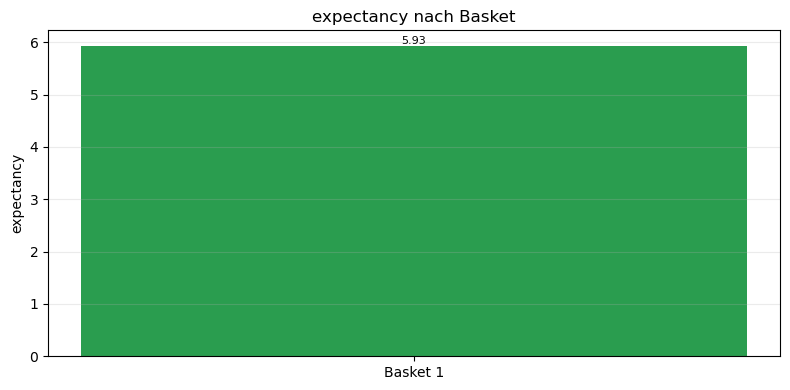

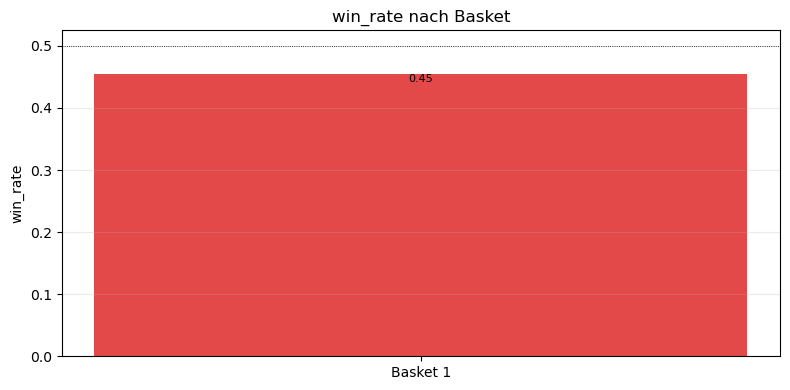

In [ ]:
best_per_basket_rows = []
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    best_per_basket_rows.append({
        "basket": basket, "candle_minutes": candle_minutes,
        "sharpe_daily": result.metrics.get("sharpe_daily", np.nan),
        "cagr_daily": result.metrics.get("cagr_daily", np.nan),
        "n_trades": result.metrics.get("n_trades", 0),
    })
best_per_basket_df = pd.DataFrame(best_per_basket_rows)
best_per_basket_best = best_per_basket_df.sort_values("sharpe_daily", ascending=False).drop_duplicates("basket").sort_values("basket")
display(best_per_basket_best)

mbb_rows = {}
for (basket, candle_minutes), result in VALIDATION_RESULTS.items():
    if basket in best_per_basket_best["basket"].values and candle_minutes == best_per_basket_best.set_index("basket").loc[basket, "candle_minutes"]:
        if not result.metrics_by_basket.empty:
            mbb_rows[basket] = result.metrics_by_basket.loc[basket]
if mbb_rows:
    mbb_combined = pd.DataFrame(mbb_rows).T
    mbb_combined.index.name = "basket"
    bt_plots.plot_basket_metric_comparison(mbb_combined, metric="expectancy")
    bt_plots.plot_basket_metric_comparison(mbb_combined, metric="win_rate", baseline=0.5)

## 13. Kerzenlängen-Vergleich (Validierung, bestes `sharpe_daily` je Kerzenlänge über alle Baskets gemittelt)

,sharpe_test_mean,sharpe_validation_mean
candle_minutes,,
5,-2.533439,0.761441
10,1.663138,-2.726285
15,2.637368,-4.635468
30,-1.514012,-2.203895


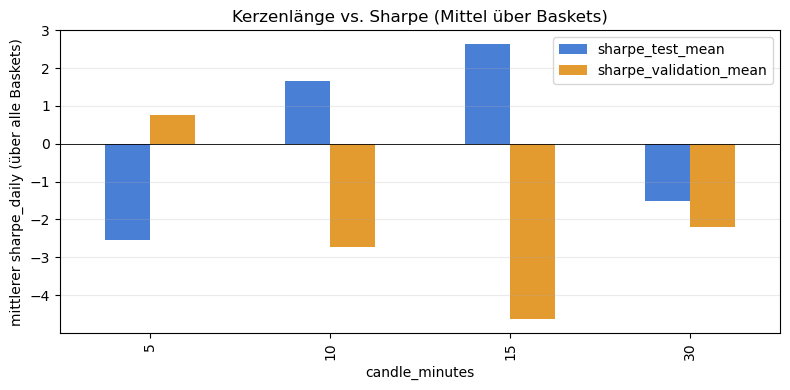

In [ ]:
candle_comparison = (
    overfit_df.groupby("candle_minutes")[["sharpe_test", "sharpe_validation"]]
    .mean()
    .rename(columns={"sharpe_test": "sharpe_test_mean", "sharpe_validation": "sharpe_validation_mean"})
)
display(candle_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
candle_comparison.plot(kind="bar", ax=ax, color=["#4a7fd6", "#e39a2e"])
ax.axhline(0, color="black", linewidth=0.6)
ax.set_ylabel("mittlerer sharpe_daily (über alle Baskets)")
ax.set_title("Kerzenlänge vs. Sharpe (Mittel über Baskets)")
ax.grid(True, alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

## 14. Gewinner-Übersicht

In [ ]:
print("Bester Basket/Kerzenlängen-Kombination je Basket (Validierung, sharpe_daily):")
display(best_per_basket_best[["basket", "candle_minutes", "sharpe_daily", "cagr_daily", "n_trades"]])

best_overall = overfit_df.sort_values("sharpe_validation", ascending=False).iloc[0]
print(f"\nGesamt-Gewinner (höchster sharpe_daily in der Validierung): "
      f"{best_overall['basket']} @ {int(best_overall['candle_minutes'])}min "
      f"(sharpe_validation={best_overall['sharpe_validation']:.3f}, sharpe_test={best_overall['sharpe_test']:.3f})")

worst_overfit = overfit_df.sort_values("sharpe_validation_minus_test").iloc[0]
print(f"Groesster Overfitting-Verdacht (sharpe faellt am staerksten von Test zu Validierung): "
      f"{worst_overfit['basket']} @ {int(worst_overfit['candle_minutes'])}min "
      f"(Δsharpe={worst_overfit['sharpe_validation_minus_test']:.3f})")

Bester Basket/Kerzenlängen-Kombination je Basket (Validierung, sharpe_daily):


,basket,candle_minutes,sharpe_daily,cagr_daily,n_trades
0,Basket 1,5,0.761441,0.005042,11



Gesamt-Gewinner (höchster sharpe_daily in der Validierung): Basket 1 @ 5min (sharpe_validation=0.761, sharpe_test=-2.533)
Groesster Overfitting-Verdacht (sharpe faellt am staerksten von Test zu Validierung): Basket 1 @ 15min (Δsharpe=-7.273)


## 15. Interpretation

_Freitext: Welche Basket/Kerzenlängen-Kombination performt am besten in der Validierung
(echtes Out-of-Sample)? Fällt die Performance von Test zu Validierung stark ab (Overfitting-
Indiz, siehe Abschnitt 7)? Gibt es eine Kerzenlänge, die über alle Baskets hinweg
systematisch besser abschneidet (Abschnitt 13)? Welche Exit-Gründe dominieren in der
Validierung im Vergleich zum Test -- deutet ein Anstieg von `stop`-Exits auf ein
Regime-abhängiges Verhalten hin?_